<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Contexte-de-l'étude" data-toc-modified-id="Contexte-de-l'étude-1">Contexte de l'étude</a></span></li><li><span><a href="#Préparation-de-l'environnement-de-travail" data-toc-modified-id="Préparation-de-l'environnement-de-travail-2">Préparation de l'environnement de travail</a></span><ul class="toc-item"><li><span><a href="#Importation-des-librairies-et-des-fonctions-personnalisées" data-toc-modified-id="Importation-des-librairies-et-des-fonctions-personnalisées-2.1">Importation des librairies et des fonctions personnalisées</a></span></li><li><span><a href="#Importation-des-jeux-de-données" data-toc-modified-id="Importation-des-jeux-de-données-2.2">Importation des jeux de données</a></span></li><li><span><a href="#Récapitulatif-des-bases-de-données" data-toc-modified-id="Récapitulatif-des-bases-de-données-2.3">Récapitulatif des bases de données</a></span></li></ul></li><li><span><a href="#Visualisations-Univariées" data-toc-modified-id="Visualisations-Univariées-3">Visualisations Univariées</a></span><ul class="toc-item"><li><span><a href="#C'est-pas-de-la-tarte" data-toc-modified-id="C'est-pas-de-la-tarte-3.1">C'est pas de la tarte</a></span></li><li><span><a href="#Un-anneau-pour-les-admirer-tous" data-toc-modified-id="Un-anneau-pour-les-admirer-tous-3.2">Un anneau pour les admirer tous</a></span></li><li><span><a href="#“L'horizon-souligne-l'infini.”" data-toc-modified-id="“L'horizon-souligne-l'infini.”-3.3">“L'horizon souligne l'infini.”</a></span></li><li><span><a href="#Barres-verticales" data-toc-modified-id="Barres-verticales-3.4">Barres verticales</a></span></li><li><span><a href="#Dupont-et-Dupond-?" data-toc-modified-id="Dupont-et-Dupond-?-3.5">Dupont et Dupond ?</a></span></li></ul></li><li><span><a href="#Visualisations-multivariées" data-toc-modified-id="Visualisations-multivariées-4">Visualisations multivariées</a></span><ul class="toc-item"><li><span><a href="#Visualisations-statiques" data-toc-modified-id="Visualisations-statiques-4.1">Visualisations statiques</a></span></li><li><span><a href="#Visualisations-intéractives" data-toc-modified-id="Visualisations-intéractives-4.2">Visualisations intéractives</a></span></li></ul></li></ul></div>

# Contexte de l'étude

Ce notebook présente les différentes visualisations des données.

L'analyse est basée sur le jeu de données Open Food Facts.

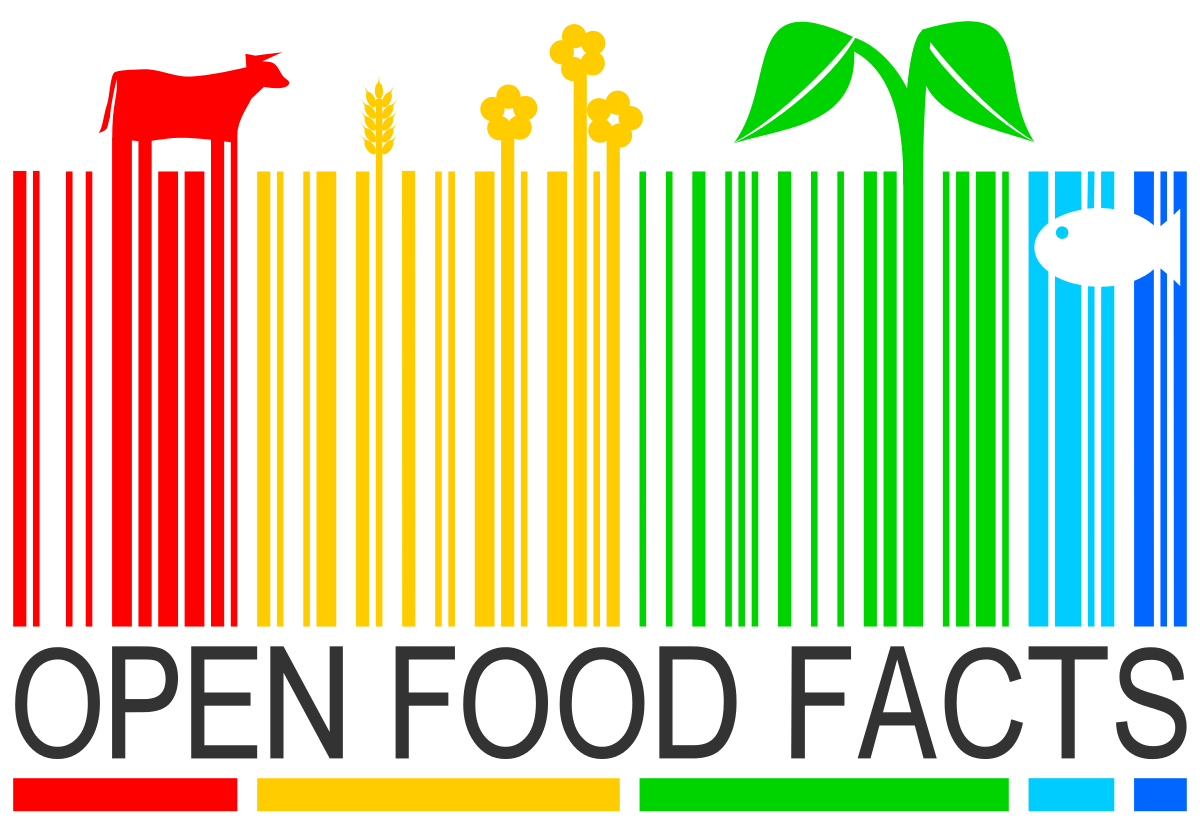

# Préparation de l'environnement de travail

## Importation des librairies et des fonctions personnalisées

Les librairies nécessaires pour l'étude sont importées dans l'environnement de travail.

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import datetime  # Manipuler dates et heures

In [2]:
from my_functions import *

## Importation des jeux de données

In [3]:
df_net = pd.read_csv(chemin + "/export_df_net.csv", sep='\t', low_memory=False)
compte_additifs = pd.read_csv(chemin + "/export_compte_additifs.csv",
                              sep='\t',
                              low_memory=False)
compte_ingredients = pd.read_csv(chemin + "/export_compte_ingredients.csv",
                                 sep='\t',
                                 low_memory=False)
data_pnns = pd.read_csv(chemin + "/export_data_pnns.csv",
                        sep='\t',
                        low_memory=False)
data_packaging = pd.read_csv(chemin + "/export_data_packaging.csv",
                             sep='\t',
                             low_memory=False)
data_matiere = pd.read_csv(chemin + "/export_data_matiere.csv",
                           sep='\t',
                           low_memory=False)

## Récapitulatif des bases de données

In [4]:
df_net.head(2)  #Base de données principale

,code,created_t,product_name,brands_tags,labels_tags,serving_quantity,additives_n,ingredients_from_palm_oil_n,ingredients_that_may_be_from_palm_oil_n,nutriscore_score,...,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,countries,solide_ou_liquide,year,boisson_ou_aliment,score_fruits_vegetables
0,0000000000017,1529059080,Vitória crackers,unknown,Unknown,2.040371e+08,2,0,0,14.0,...,0.56,0.01246,0.077388,0.144409,0.015516,France,Unknown,2018,aliment,0
1,000000000003327986,1574175736,Filetes de pollo empanado,unknown,Unknown,2.040371e+08,2,0,0,9.0,...,0.44,0.01246,0.077388,0.144409,0.015516,Espagne,Unknown,2019,aliment,0


In [5]:
df_description = data_informations(df_net)

---------------------------INFORMATION SUR LA BASE DE DONNEES-----------------------------------------------
Nombre de variables : 37
Nombre d'observations : 1527078
---------------------------VALEURS MANQUANTES---------------------------------------------------------------
Nombre de cellules avec des données manquantes :  2
Pourcentage du nombre de cellules avec des données manquantes :  0.0  %
Nombre de lignes avec au moins une donnée manquante :  2
Pourcentage de lignes avec au moins une donnée manquante :  0.0  %
---------------------------VALEURS DUPLIQUEES---------------------------------------------------------------
Nombre de doublons dans la base de données :  0
Pourcentage de doublons dans la base de données :  0.0  %
---------------------------VALEURS OUTLIERS-----------------------------------------------------------------
Nombre de cellules avec des outliers :  1853986
Pourcentage du nombre de cellules avec des outliers :  3.3  %
Nombre de lignes avec au moins un outlier :

In [6]:
print(
    f"La base de données contient {df_net.select_dtypes(exclude='object').shape[1]} variables quantitatives",
    f" et {df_net.select_dtypes(include='object').shape[1]} variables qualitatives")

La base de données contient 25 variables quantitatives  et 12 variables qualitatives


In [7]:
compte_additifs.head(2
)  #Base de données qui donne le nombre d'additifs dans l'ensemble de la base de données df_net

,Nom_Additif,Nombre
0,Unknown,1144572
1,E330,124179


In [8]:
compte_ingredients['Nom_Ingredient'] = compte_ingredients[
    'Nom_Ingredient'].str.lower()
compte_ingredients.head(2
)  #Base de données qui donne le nombre d'additifs dans l'ensemble de la base de données df_net

,Nom_Ingredient,Nombre
0,unknown,890533
1,salt,355047


In [9]:
data_pnns.head(2)

,Groupement 02,Nombre,Groupement 01
0,unknown,873484,unknown
1,Sweets,62081,Sugary snacks


# Visualisations Univariées

## C'est pas de la tarte

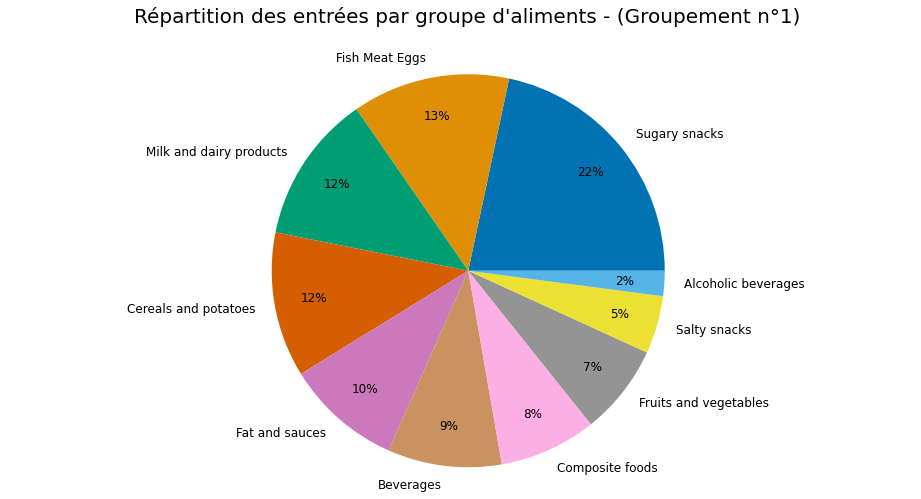

In [10]:
big_pie_sans_unk_1col(df_net, 'pnns_groups_1', 'unknown')
plt.title("Répartition des entrées par groupe d'aliments - (Groupement n°1)",
          fontsize=20,
          pad=30)
plt.show()

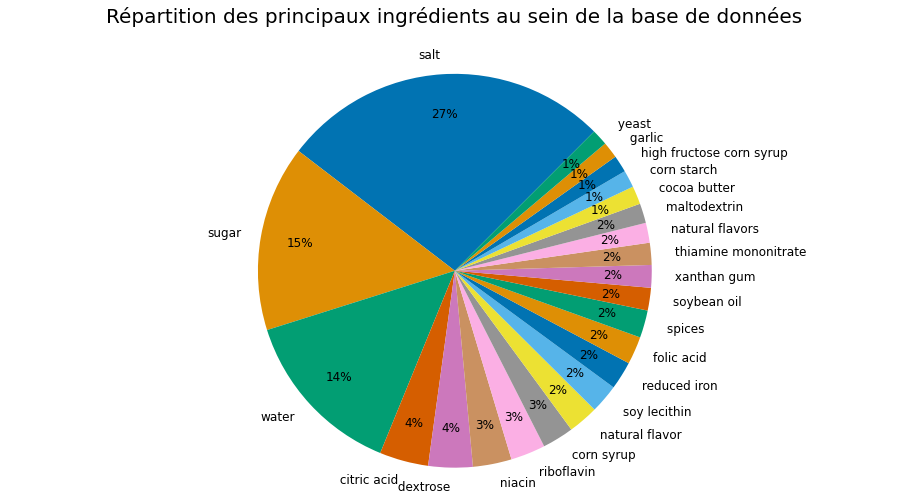

In [11]:
big_pie_sans_unk_2col(compte_ingredients, 'Nom_Ingredient', 'Nombre',
                      'unknown')
plt.title(
    "Répartition des principaux ingrédients au sein de la base de données",
    fontsize=20,
    pad=30)
plt.show()  # Affiche le graphique

## Un anneau pour les admirer tous

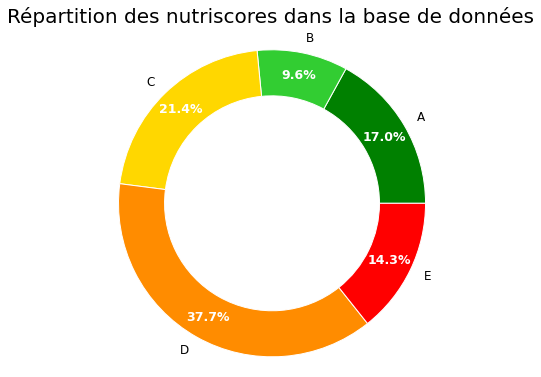

In [12]:
score_ring(df_net, 'nutriscore_grade', 'unknown')
plt.title("Répartition des nutriscores dans la base de données",
          fontsize=20,
          pad=15)
plt.show()

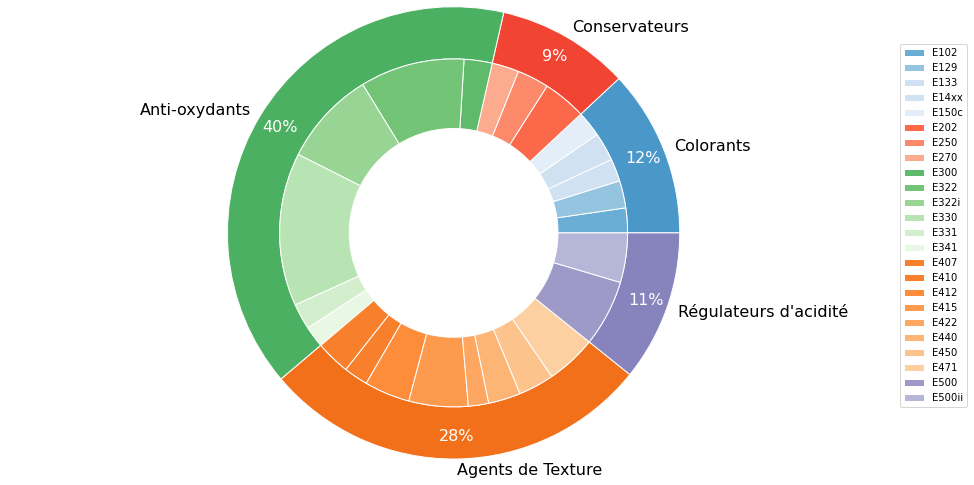

In [13]:
two_rings_additifs(compte_additifs)

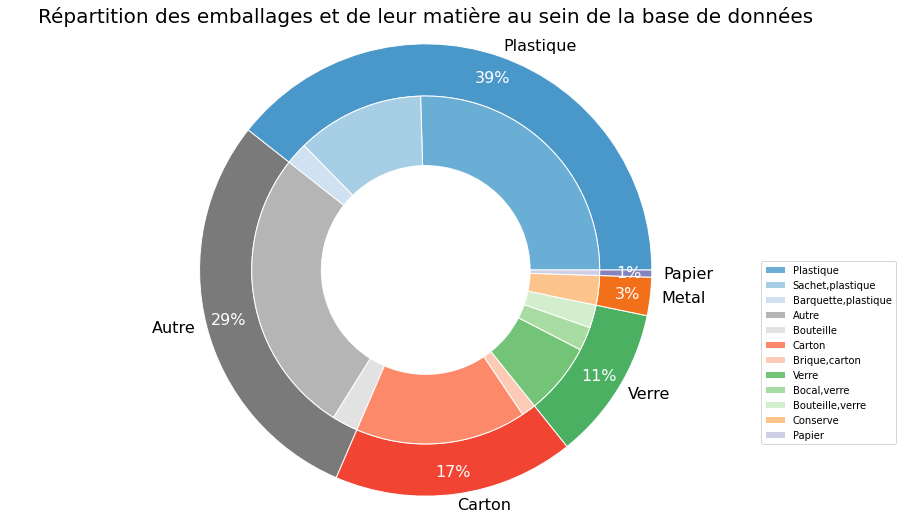

In [14]:
two_rings_emballage(data_packaging, data_matiere)
plt.show()

## “L'horizon souligne l'infini.”

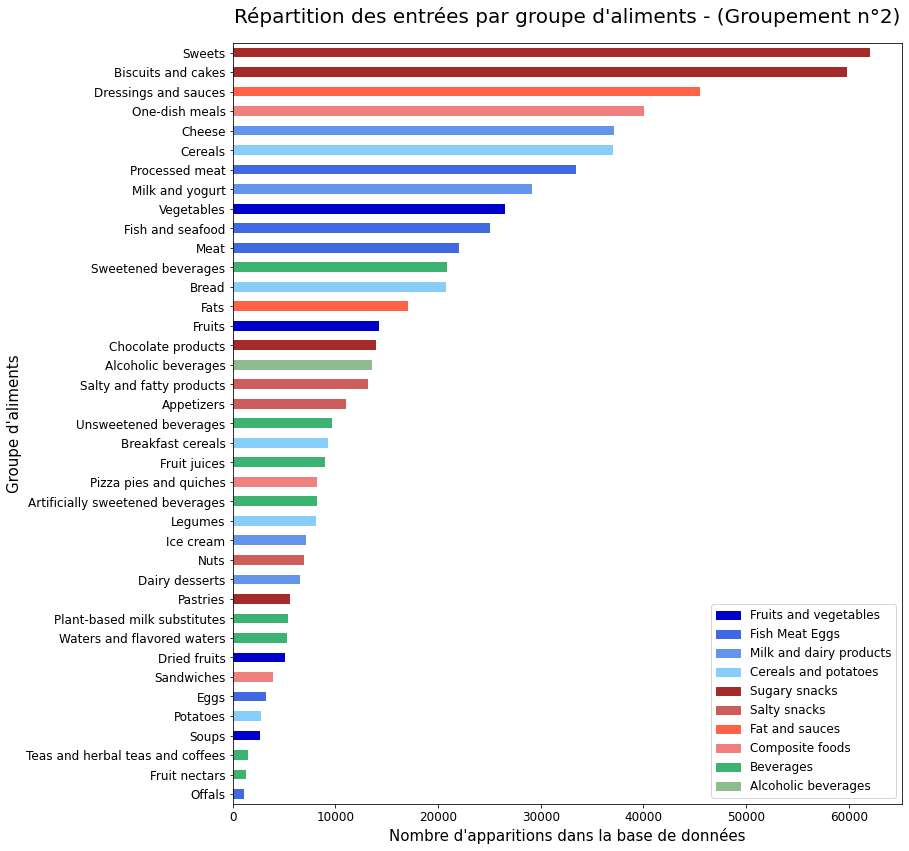

In [15]:
barh_colors(data_pnns)
plt.title("Répartition des entrées par groupe d'aliments - (Groupement n°2)",
          fontsize=20,
          pad=20)
plt.ylabel("Groupe d'aliments", fontsize=15)
plt.xlabel("Nombre d'apparitions dans la base de données", fontsize=15)
plt.show()

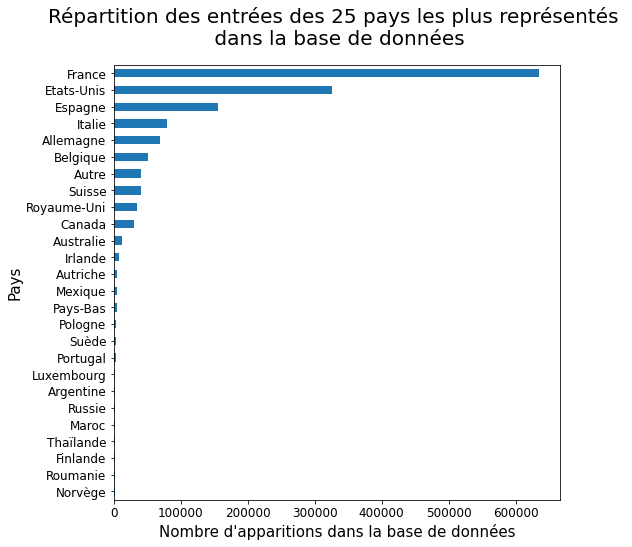

In [16]:
barh_sans_unk_1col(df_net, 'countries', 'unknown')
plt.title(
    "Répartition des entrées des 25 pays les plus représentés \n dans la base de données",
    fontsize=20,
    pad=20)
plt.ylabel("Pays", fontsize=15)
plt.show()

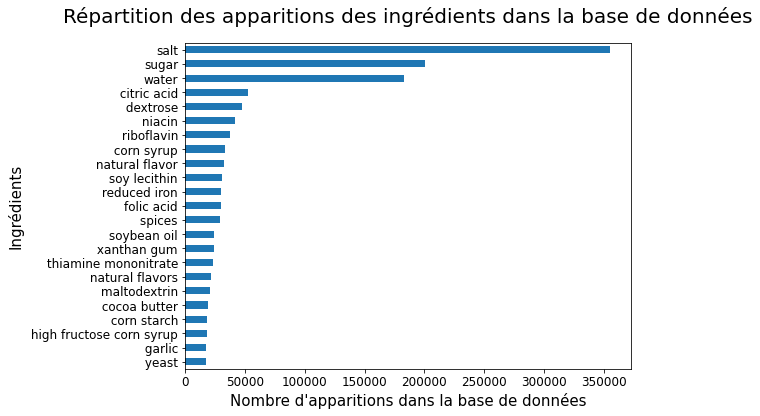

In [17]:
barh_sans_unk_2col(compte_ingredients, 'Nom_Ingredient', 'Nombre', 'unknown')
plt.title(
    "Répartition des apparitions des ingrédients dans la base de données",
    fontsize=20,
    pad=20)
plt.ylabel('Ingrédients', fontsize=15)
plt.show()  # Affiche le graphique

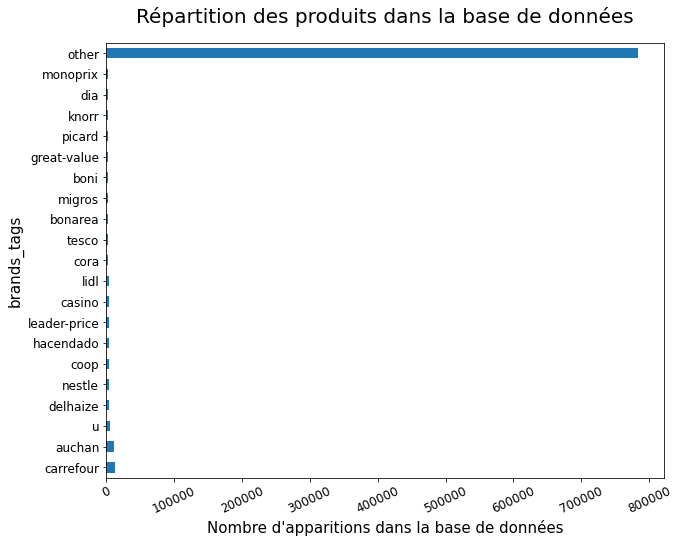

In [18]:
data = df_net.drop(df_net[df_net.brands_tags == 'unknown'].index)
ax = representation_other(data, 'brands_tags', 0.0025)
plt.show()

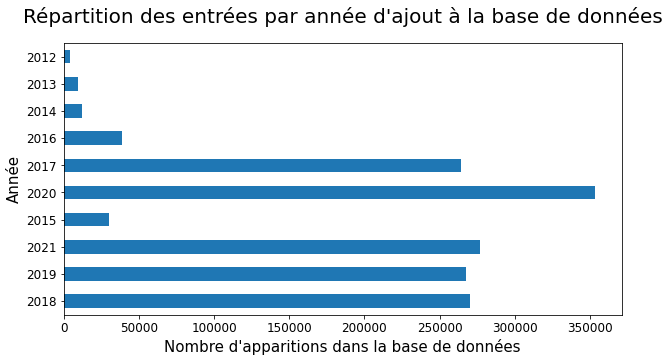

In [19]:
barh_quanti(df_net, 'year')
plt.title("Répartition des entrées par année d'ajout à la base de données",
          fontsize=20,
          pad=20)
plt.ylabel('Année', fontsize=15)
plt.show()

## Barres verticales

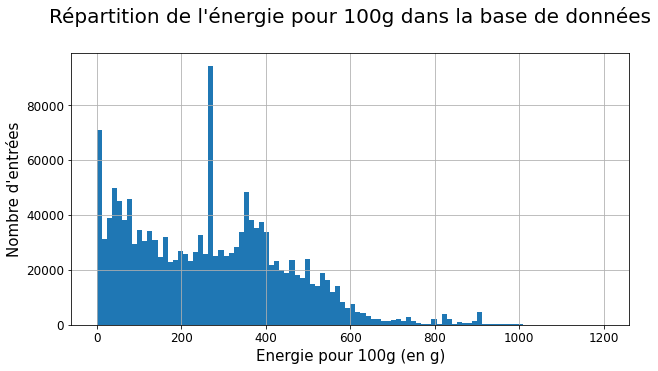

In [20]:
barv_quanti(df_net, 'energy-kcal_100g')
plt.title("Répartition de l'énergie pour 100g dans la base de données",
          fontsize=20,
          pad=30)
plt.xlabel("Energie pour 100g (en g)", fontsize=15)
plt.show()

## Dupont et Dupond ?

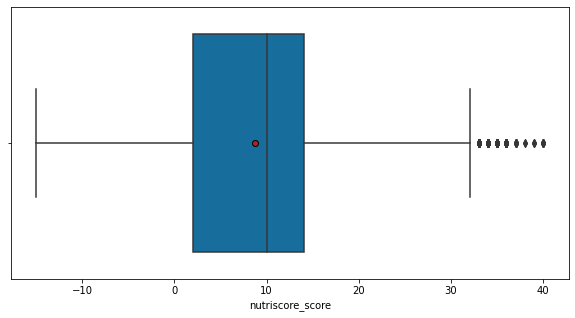

In [21]:
plt.rcParams["figure.figsize"] = (10, 5)
meanprops = {
    'marker': 'o',
    'markeredgecolor': 'black',
    'markerfacecolor': 'firebrick'
}
ax = sns.boxplot(x=df_net['nutriscore_score'],
                 palette="colorblind",
                 showmeans=True,
                 meanprops=meanprops)
plt.show()

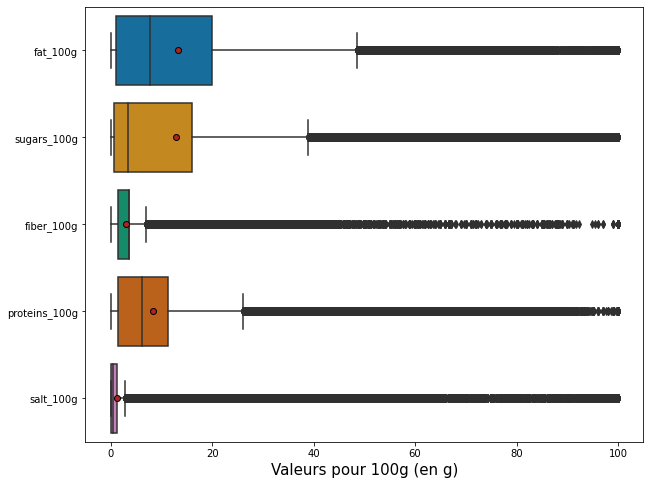

In [22]:
moustask(
    df_net,
    ['fat_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g'])

plt.xlabel("Valeurs pour 100g (en g)", fontsize=15)
plt.show()

# Visualisations multivariées

## Visualisations statiques

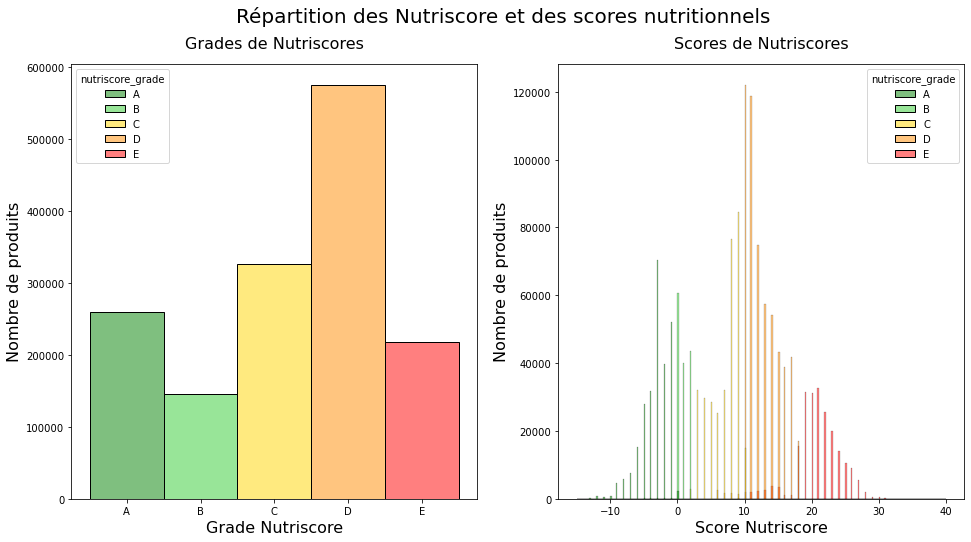

In [23]:
visualisation_nutri(df_net)

## Visualisations intéractives

In [24]:
columns_quali = ['nutriscore_grade']
columns_quanti = [
    'nutriscore_score', 'energy-kcal_100g', 'fat_100g', 'sugars_100g',
    'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g'
]
%matplotlib widget
interactif_plot(df_net, 10000, columns_quali, columns_quanti)

interactive(children=(Dropdown(description='variable1', options=('nutriscore_grade', 'nutriscore_score', 'ener…

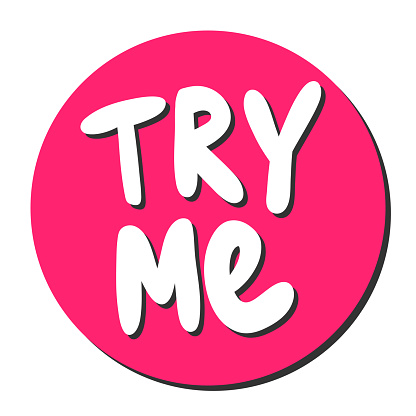

In [25]:
visualisation_nutri_year(df_net)

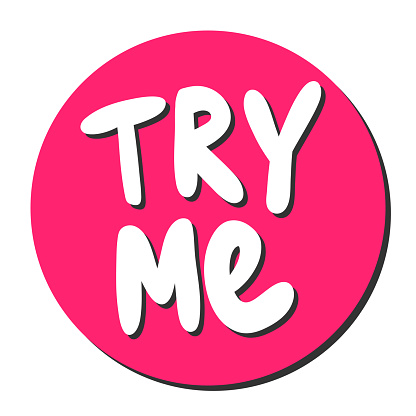

In [26]:
visualisation_map(df_net, 10000)

In [27]:
%matplotlib inline